In [ ]:
%%writefile vectorAdd.cu
#include <stdio.h>
#include <stdlib.h>
#include <time.h>
#include <sys/time.h>


double cpuSecond()
{
   struct timeval tp;
   gettimeofday(&tp,NULL);
   return ((double)tp.tv_sec + (double)tp.tv_usec*1.e-6);
}

__global__ void vectorAddKernel( float *A, float *B, float *C, int N)
{
  int i = blockIdx.x * blockDim.x + threadIdx.x;

  if(i < N)
    {
      C[i] = A[i] + B[i];
    }
}

int main()
{
  srand(time(NULL));
  int N_values[10] = {10000, 50000, 100000, 250000, 500000, 1000000, 2500000, 5000000, 7500000, 10000000};
  printf("N, H2D_Time_s, Kernel_Time_s, D2H_Time_s\n");
  for (int t = 0; t < 10; t++)
  {
      int N = N_values[t];
      size_t size = N * sizeof(float);

    float *h_A = (float *)malloc(size);
    float *h_B = (float *)malloc(size);
    float *h_result = (float *)malloc(size);
  for(int i = 0; i < N; i++)
  {
    h_A[i] = float(rand()%100);
    h_B[i] = float(rand()%100);
  }
  for(int i = 0; i < N; i++)
  {
    h_result[i] = h_A[i] + h_B[i];
  }
  printf("CPU result = %f + %f = %f\n", h_A[0], h_B[0], h_result[0]);

// GPU setup

float *d_A, *d_B, *d_result;

cudaMalloc((void **)&d_A, size);
cudaMalloc((void **)&d_B, size);
cudaMalloc((void **)&d_result, size);

double start_H2D = cpuSecond();
cudaMemcpy(d_A, h_A, size, cudaMemcpyHostToDevice);
cudaMemcpy(d_B, h_B, size, cudaMemcpyHostToDevice);
double time_H2D = cpuSecond() - start_H2D;

int threads = 512;
int blocksPerGrid = (N + threads - 1) / threads;

double start_Kernel = cpuSecond();
vectorAddKernel<<<blocksPerGrid, threads>>>(d_A, d_B, d_result, N);
cudaDeviceSynchronize();
double time_Kernel = cpuSecond() - start_Kernel;

double start_D2H = cpuSecond();
cudaMemcpy(h_result, d_result, size, cudaMemcpyDeviceToHost);
double time_D2H = cpuSecond() - start_D2H;

printf("%d, %f, %f, %f\n", N, time_H2D, time_Kernel, time_D2H);

printf("GPU result: %f + %f = %f\n", h_A[0], h_B[0], h_result[0]);

free(h_A);
free(h_B);
free(h_result);

cudaFree(d_A);
cudaFree(d_B);
cudaFree(d_result);
  }
return 0;
}


Writing vectorAdd.cu


In [ ]:
!nvcc vectorAdd.cu -o vectorAdd
!./vectorAdd

N, H2D_Time_s, Kernel_Time_s, D2H_Time_s
CPU result = 95.000000 + 16.000000 = 111.000000
10000, 0.000059, 0.000110, 0.000026
GPU result: 95.000000 + 16.000000 = 111.000000
CPU result = 34.000000 + 23.000000 = 57.000000
50000, 0.000113, 0.000029, 0.000065
GPU result: 34.000000 + 23.000000 = 57.000000
CPU result = 55.000000 + 15.000000 = 70.000000
100000, 0.000243, 0.000045, 0.000113
GPU result: 55.000000 + 15.000000 = 70.000000
CPU result = 38.000000 + 5.000000 = 43.000000
250000, 0.000597, 0.000102, 0.000304
GPU result: 38.000000 + 5.000000 = 43.000000
CPU result = 65.000000 + 60.000000 = 125.000000
500000, 0.000894, 0.000103, 0.000446
GPU result: 65.000000 + 60.000000 = 125.000000
CPU result = 2.000000 + 94.000000 = 96.000000
1000000, 0.001648, 0.000119, 0.000795
GPU result: 2.000000 + 94.000000 = 96.000000
CPU result = 78.000000 + 26.000000 = 104.000000
2500000, 0.004353, 0.000167, 0.002074
GPU result: 78.000000 + 26.000000 = 104.000000
CPU result = 72.000000 + 31.000000 = 103.000000

In [ ]:
!ncu ./vectorAdd

CPU result = 43.000000 + 77.000000 = 120.000000
==PROF== Connected to process 20401 (/content/vectorAdd)
==PROF== Profiling "vectorAddKernel" - 0: 0%....50%....100% - 9 passes
GPU result: 43.000000 + 77.000000 = 120.000000
==PROF== Disconnected from process 20401
[20401] vectorAdd@127.0.0.1
  vectorAddKernel(float *, float *, float *, int) (514, 1, 1)x(512, 1, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: GPU Speed Of Light Throughput
    ----------------------- ----------- ------------
    Metric Name             Metric Unit Metric Value
    ----------------------- ----------- ------------
    DRAM Frequency                  Ghz         4.64
    SM Frequency                    Mhz       581.24
    Elapsed Cycles                cycle        7,964
    Memory Throughput                 %        63.91
    DRAM Throughput                   %        63.91
    Duration                         us        13.70
    L1/TEX Cache Throughput           %        28.40
    L2 Cache Throughpu

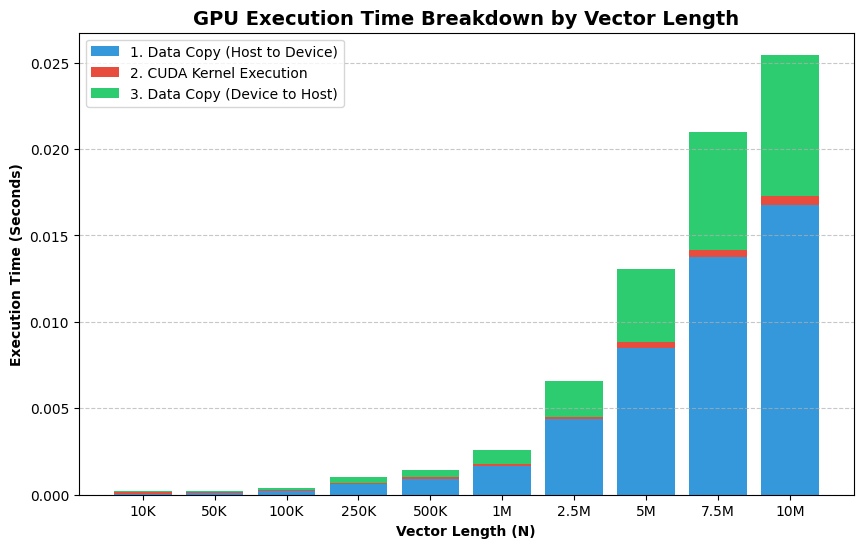

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

N_values = ['10K', '50K', '100K', '250K', '500K', '1M', '2.5M', '5M', '7.5M', '10M']
h2d_times = [0.000059, 0.000113, 0.000243, 0.000597, 0.000894, 0.001648, 0.004353, 0.008515, 0.013761, 0.016777]
kernel_times = [0.000110, 0.000029, 0.000045, 0.000102, 0.000103, 0.000119, 0.000167, 0.000309, 0.000394, 0.000528]
d2h_times = [0.000026, 0.000065, 0.000113, 0.000304, 0.000446, 0.000795, 0.002074, 0.004256, 0.006848, 0.008148]

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(N_values, h2d_times, label='1. Data Copy (Host to Device)', color='#3498db')
ax.bar(N_values, kernel_times, bottom=h2d_times, label='2. CUDA Kernel Execution', color='#e74c3c')

bottom_d2h = np.add(h2d_times, kernel_times)
ax.bar(N_values, d2h_times, bottom=bottom_d2h, label='3. Data Copy (Device to Host)', color='#2ecc71')

ax.set_xlabel('Vector Length (N)', fontweight='bold')
ax.set_ylabel('Execution Time (Seconds)', fontweight='bold')
ax.set_title('GPU Execution Time Breakdown by Vector Length', fontweight='bold', fontsize=14)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()